   ... Haskell's lazy evaluation model, reducing an expression to Weak-Head
   Normal Form (WHNF) fundamentally alters the time com plexity of algorithms
   compared to strict Normal Form (evaluation)...

   for instance, finding the minimum element of a list using 
   `minimum xs = head (isort xs)` requires `O(n^2)` time in a strict language
   because the entire list must be sortede ... but the cost drops just to 
   `O(n)` time n Haskell...

---




-- In haskell, both `putStrLn` and `print` displays output to the terminal
   followed by a new line... `putStrLn` only accepts a `String` and 
   prints it as is... whereas `print` accepts any type in the `Show` typeclass
   and converts it to a string first ... 

   Essentially, `print` is defiend as `putStrLn . show`



-- In function signatures ... the part before `=>` is a typeclass constraint on 
   the type variables in the function signature ... In 

   `sort :: Ord => [a] -> [a]`

   it means `a` can be any type as long as that type is an instance of `Ord`.
   Because of that constraint you can use methods like ... `compare` and 
   `<` inside the function body. The compiler checks every call and rejects a 
   type that has no `Ord` instance. Behidn the scenes GHC passes a hidden 
   directory of the class methods 

---


   ... in hskell, `TELESCOPING` refers to a recursive pattern--or a sequence of
   dependent types--where each step expands or builds upon the previous one like
   the sliding segments of a spyglass ... In .... telescoping describes a 
   computation that lazily unfolds in progressively larger chunks o... minimal
   memory overhead ... 

   ... both folds collapse a list into one value with a function and a starting
   value. `foldr` ... groups from the right and its function takes the element
   first and the accumulator second ... `foldl groups from the left, and
   its function takes `

---


| Construct | Syntax Example | Cost Formula | What this means |
| --- | --- | --- | --- |
| **Variables** | `x` | $0$ | Variable lookups are free. |
| **Constants** | `k` (e.g., `0`, `[]`) | $0$ | Loading constants is free. |
| **Primitive Functions** | `null`, `(+)`, `tail` | $0$ | Built-in primitive function calls do not add cost. |
| **User-Defined Functions** | `f x1 .. xn = e` | $1 + T(e)$ | Calling a function you defined costs $1$ step, plus whatever it costs to evaluate the function's inner body ($e$). |
| **Function Application** | `f e1 .. en` | $T(f) e_1 .. e_n + T(e_1) + .. + T(e_n)$ | You pay for the cost of evaluating the function itself, plus the cost of evaluating every argument you passed to it. |
| **Conditionals** | `if e then e1 else e2` | $T(e) + \text{if } e \text{ then } T(e_1) \text{ else } T(e_2)$ | You pay to evaluate the condition ($e$), plus the cost of *only* the specific branch that gets executed. |
| **Pattern Matching** | `case e1 of [] -> e2; (x:xs) -> e3` | $T(e_1) + \text{case } e_1 \text{ of } [] \rightarrow T(e_2); (x:xs) \rightarrow T(e_3)$ | Similar to an `if` statement, the pattern matching mechanism itself is free; you only pay to evaluate the expression being matched ($e_1$) and the cost of the branch that gets selected. |


-- 

-- ... the pattern matching mechanism itself is free... you only pay to 
   evaluate the expression being matched ($e_1$) and the cost of the branch
   that gets selected...



---

   ... the requirement specifically describes the mathematical concept of an
   identity element within a Monoid. Because `foldl` feeds the accumulator 
   as the first argument ... the starting value `k` must not alter the data
   from either direction. If you use addition, the zero is loiterally the number
   zero because .... if you use the list append fucntion instead, the zero is
   the empty list `[]`

   ... if your initial value does not dissapear when applied from boths ides ... 
   the two folds will produce completely different results ... you are 
   guaranteeing that the baseline accumulator has absolutely no impact on the 
   final computed value ... function must also be assosciative to ensure the
   bracket grouping does not change the final answer. this mathematical
   property is strictly required for the folds to mirror each other. together
   these rules allow you to safely swap between left and right folds while
   guaranteeing the exact same logical output... 

   A monoid requires a binary operation, and it needs a neutral identity 
   element. The operation must be strictly assosciative ... 

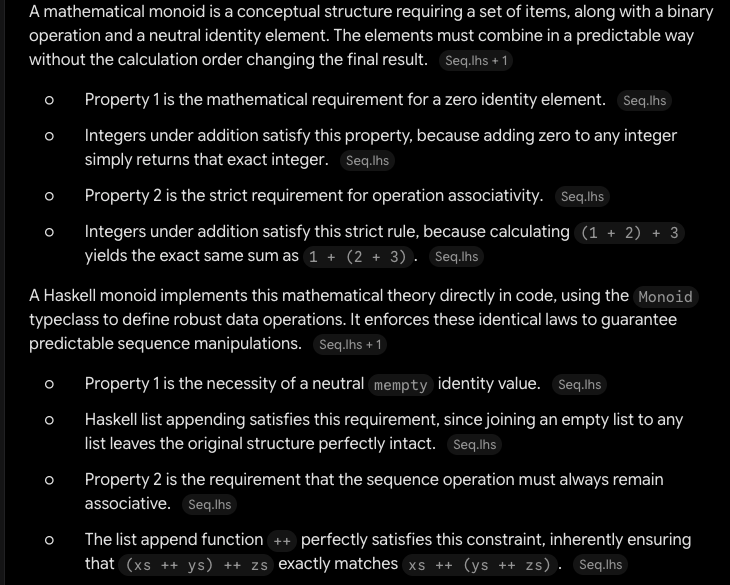


---

   Big-O notation explicitly defines the asymptotic upper bound of an algorithm
   cost function. This notation fundamentally represents the worst-case execution 
   time for your evaluated profram. An $O(N^2)$ designation means the required
   time will strictly scale quadratically as the input grows. The underlying 
   mathematical definition guarantees the function will never exceed this 
   max bounding limit ... in tree extraction example, a purely left-biased tree
   heavily triggers this exact maximum limit...

   Big-Omega notation mathematically establishes the absolute asymptotic lower
   bound of an evaluated function. This metric dicates the absolute minimum
   execution time required to complete the algorithmic task ... 

   An Big-Omega(N) complexity proves the specified function requires at least
   linear time to finish... the program cannot possibly execute faster than this
   firm mathematical baseline. Looking ... 



```hs
data Tree a = Leaf a | Fork (Tree a) (Tree a)

values :: Tree a -> [a]
values (Leaf x) = [x]
values (Fork lt rt) = values rt ++ values lt
```

   This segment demonstrates how you can swap underlying data representations
   to optimise specific algorithmic costs without changing how the functions
   are called...

   It first establishes the standard Haskell list (`[]`) as the 
   `canonical sequence`... by implementing the `Seq` typeclass for it. For a 
   standard list, calculating the total size requires an $O(n)$ traversal to 
   count every element. The `toList`... are defined as universal
   conversion tools... allowing you to trnaform any custom sequence back into this 
   standard baseline list formt.... 

   To show how performance can be intentionally manipulated, the snippet then 
   introduces a new type called `LenList`. This structure fundamentally wraps
   a standard list but pairs it with an integer that continuously tracks the 
   number of elements inside. By catching this numerical count in memory, the algorithmic
   cost for the `length` and `null` queries drops from an O(n) linear traversal
   down to an instantaneous O(1) lookup... In exchange for this optimised query
   speed, constructive operations like `cons` and append are forced to perform
   basic arithemtic (`n+ 1 ` or `m + n`)... to keep the cached integer
   accurate as the list grows... 

In [ ]:
   This segment introduces an array as another possible sequence representation,
   which perfectly optimises data querying... Arrays provide instantaneous 
   constant-time lookups for operations like checking the length or finding the
   last element. However they perform terribly for structural modifications...
   forcing linear-time costs whenever you append or add items ... The text
   notes that arrays are ideal for fixed-size data, but they fail to solve the 
   earlier three extraction problem. For that specific algorithm, we 
   desperately need a data structure where appending lists is extremel cheap...

   To achieve this fast append operation, the ... ingeniously pivots to 
   mathematical function composition. Function composition is inherently
   associative, meaning the bracketing order never changes the final executed 
   logic ... 

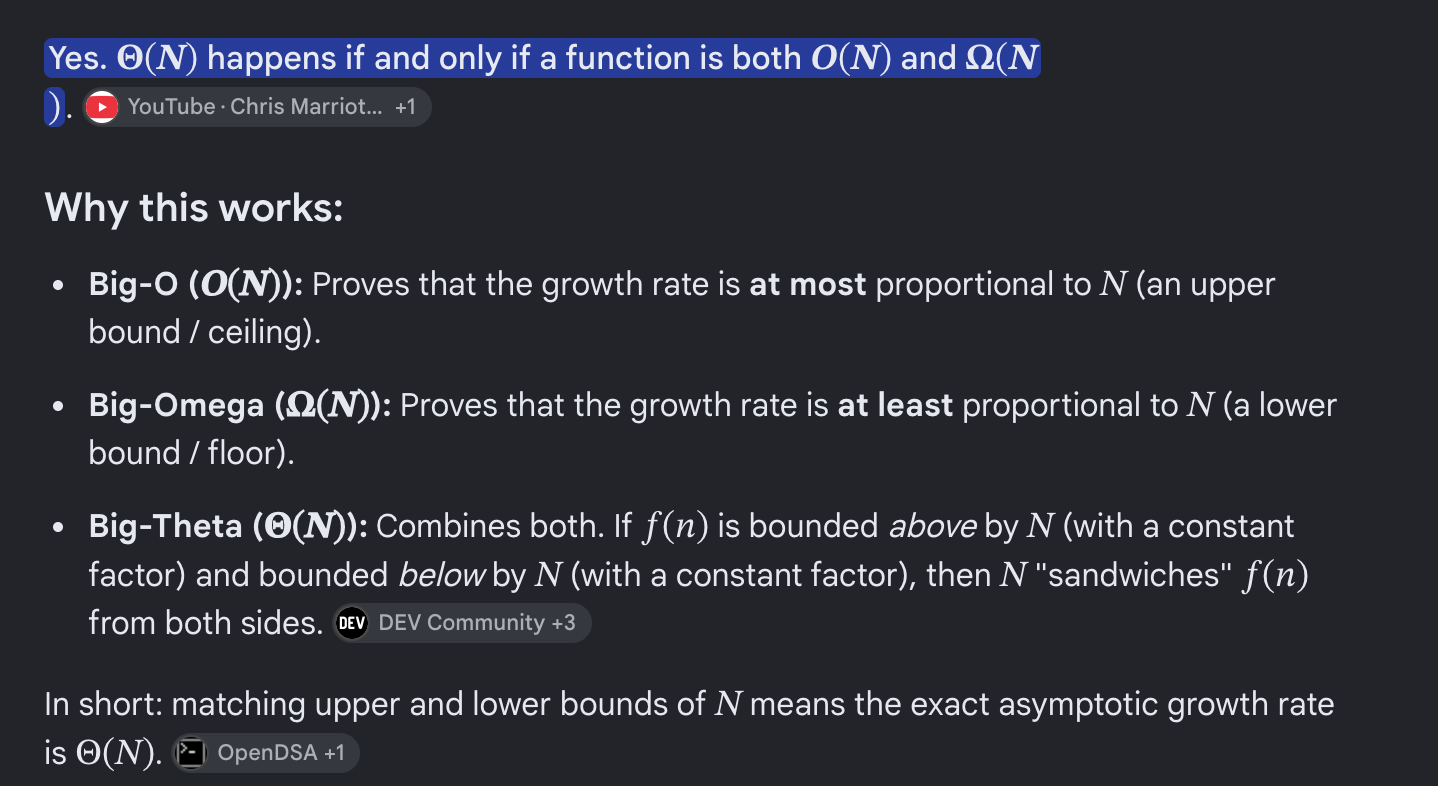

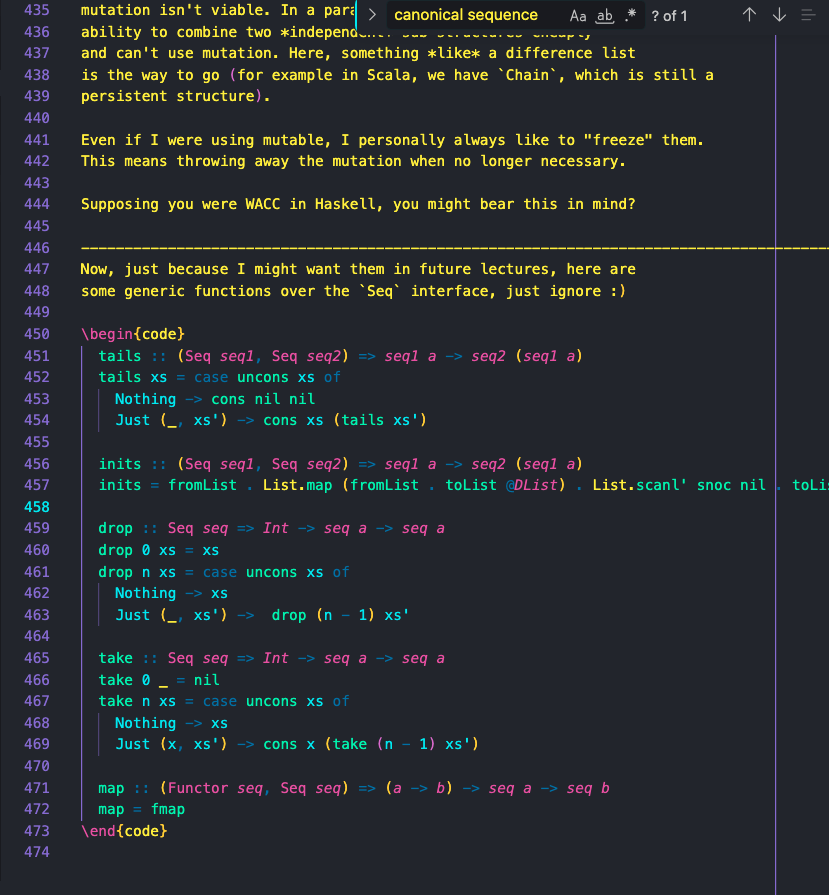